# 03 · Modelos supervisados: riesgo de mora e inspecciones
**Facturación residencial de energía eléctrica, 2023–2024**

Este notebook cubre las fases **3.7 y 3.8** de la guía y las problemáticas **4.5 y 4.6**.

- **Entrada:** `data/datos_limpios.parquet` generado por la 01. **No vuelve a limpiar el CSV ni sobrescribe el parquet.**
- **Salida:** `data/top_1000_cuentas_inspeccion.csv` con las cuentas no inspeccionadas de mayor riesgo.
- **Unidad de análisis:** la cuenta. El árbol predice mora de más de 60 días en el segundo semestre de 2024; el bosque predice el resultado de una inspección técnica.
- **Regla:** nunca se usan datos posteriores al momento de la predicción; el corte temporal está en el código, no en el azar.


In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, precision_score, recall_score, f1_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

RUTA_DATOS = Path('data/datos_limpios.parquet')
if not RUTA_DATOS.exists():
    raise FileNotFoundError('Ejecuta primero 01_limpieza_y_exploratorio.ipynb: no existe data/datos_limpios.parquet')

df = pd.read_parquet(RUTA_DATOS)
requeridas = ['id_cuenta', 'periodo', 'estrato', 'operador', 'tipo_medidor', 'consumo_kwh',
              'valor_total_cop', 'dias_mora', 'lectura_estimada', 'autogeneracion_solar',
              'resultado_inspeccion']
faltantes = [c for c in requeridas if c not in df.columns]
if faltantes:
    raise ValueError(f'El parquet no tiene las columnas esperadas: {faltantes}. Vuelve a ejecutar la 01.')

print(f'Filas: {len(df):,} | Cuentas: {df["id_cuenta"].nunique():,}')
print(f'Periodos: {df["periodo"].min()} a {df["periodo"].max()}')
print('Este notebook solo lee el parquet: no vuelve a limpiar el CSV ni lo sobrescribe.')


Filas: 2,472,616 | Cuentas: 109,938
Periodos: 2023-01 a 2024-12
Este notebook solo lee el parquet: no vuelve a limpiar el CSV ni lo sobrescribe.


## Fase 3.7 / Problemática 4.5 · ¿Qué cuentas terminarán con mora de más de 60 días?

Se arma una tabla con una fila por cuenta usando **solo información hasta 2024-06**:
consumo y facturación promedio de 2023, meses con mora en 2023 y factura promedio del
primer semestre de 2024. El objetivo es si la cuenta acumuló **mora > 60 días en 2024-07..12**.

Se ajusta un árbol poco profundo (`max_depth=4`, `min_samples_leaf=500`, `class_weight='balanced'`)
para que las reglas quepan en una página y se puedan leer como criterios de negocio.

Las reglas se imprimen en texto y se dibujan como imagen dentro de la misma celda: cada camino de la raíz a una hoja es una regla, y el color resume la clase dominante con el balanceo de clases activo.
Como el árbol usa `class_weight="balanced"`, en la imagen el tamaño del nodo es el número real de cuentas (`samples`) pero los `value` y los colores son **ponderados**: sirven para leer la regla, no para estimar la proporción real de morosos (9,14%).


Cuentas con facturación 2023 en cero (se descartan): 1
Cuentas modelables: 103,870 | con mora > 60 en 2024-07..12: 9.14%
test_precision: 0.164
test_recall: 0.693
test_f1: 0.265
test_roc_auc: 0.723


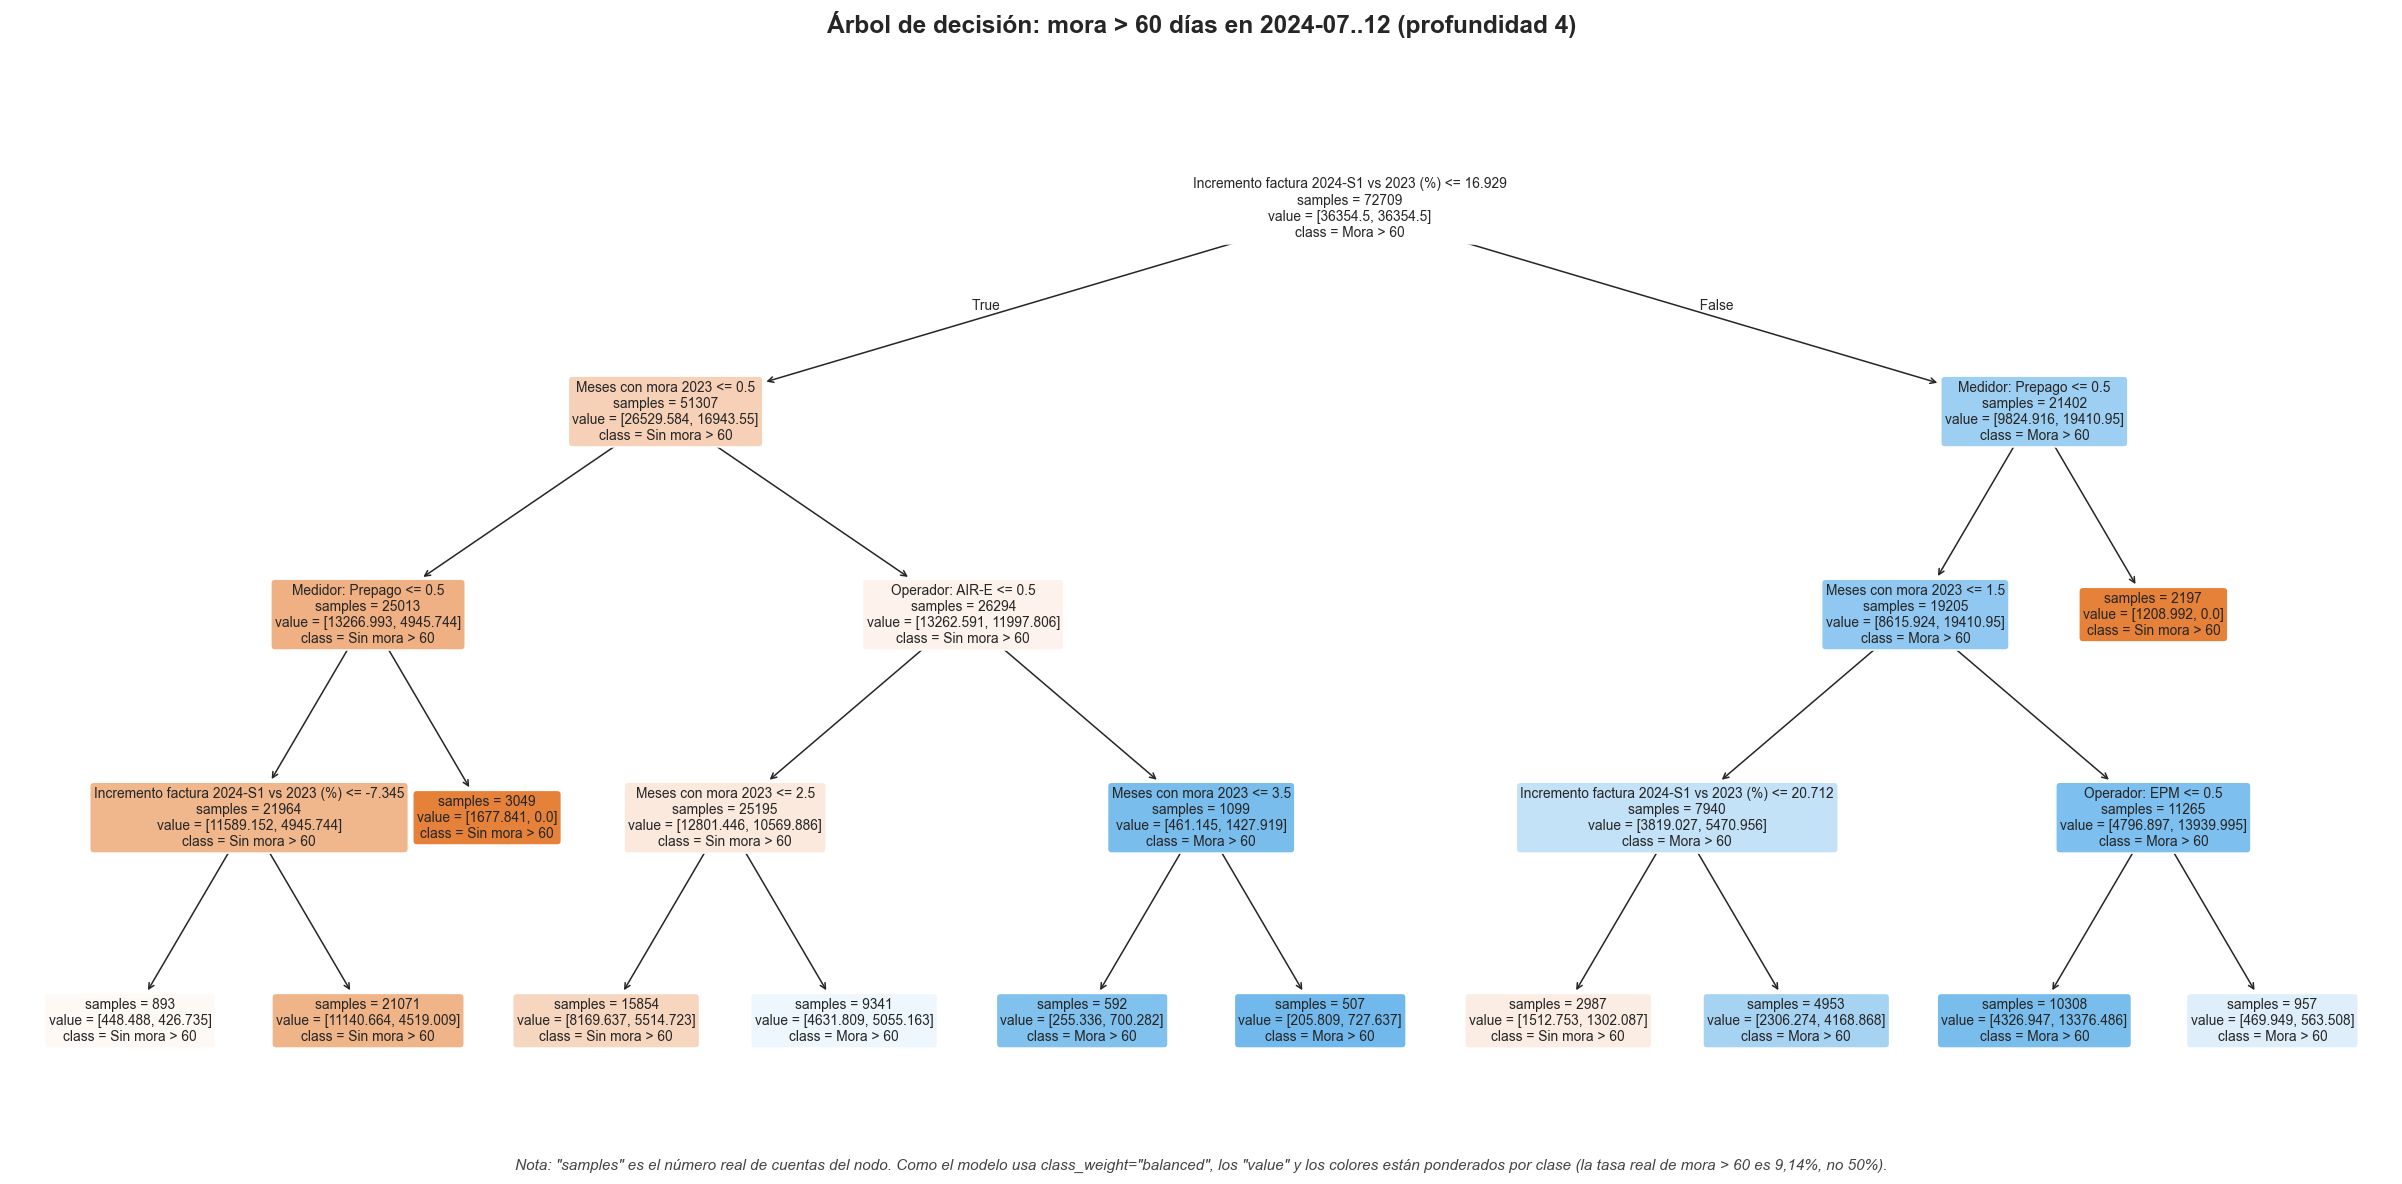


Reporte en Test:
               precision    recall  f1-score   support

         0.0       0.95      0.66      0.78     28313
         1.0       0.16      0.67      0.26      2848

    accuracy                           0.66     31161
   macro avg       0.56      0.66      0.52     31161
weighted avg       0.88      0.66      0.73     31161


Reglas del Árbol:
 |--- Incremento factura 2024-S1 vs 2023 (%) <= 16.93
|   |--- Meses con mora 2023 <= 0.50
|   |   |--- Medidor: Prepago <= 0.50
|   |   |   |--- Incremento factura 2024-S1 vs 2023 (%) <= -7.34
|   |   |   |   |--- class: 0.0
|   |   |   |--- Incremento factura 2024-S1 vs 2023 (%) >  -7.34
|   |   |   |   |--- class: 0.0
|   |   |--- Medidor: Prepago >  0.50
|   |   |   |--- class: 0.0
|   |--- Meses con mora 2023 >  0.50
|   |   |--- Operador: AIR-E <= 0.50
|   |   |   |--- Meses con mora 2023 <= 2.50
|   |   |   |   |--- class: 0.0
|   |   |   |--- Meses con mora 2023 >  2.50
|   |   |   |   |--- class: 1.0
|   |   |--- Opera

region,Caribe,Resto del país
tramo_inc,,
<=0%,21.62,7.06
0-15%,19.91,5.05
15-30%,19.99,6.01
>30%,23.66,13.21



Lectura rápida:
  Cada fila de la tabla anterior es el % de cuentas que terminó con mora > 60 días,
  por tramo de incremento de la factura y por región. Si el % crece con el tramo,
  el incremento de la factura anticipa la mora; si el Caribe está por encima en todos
  los tramos, el efecto es de la región y no solo del alza.


In [4]:
# ============================================================
# FASE 3.7 / PROBLEMÁTICA 4.5 - Árbol de decisión: mora > 60 días en 2024-07..12
# Corte temporal explícito: se aprende con el pasado y se evalúa con el futuro.
# ============================================================
hist = df[df['periodo'] <= '2024-06']
futuro = df[df['periodo'] >= '2024-07']

y_mora = futuro.groupby('id_cuenta')['dias_mora'].apply(lambda x: int((x > 60).any()))

f_2023 = hist[hist['periodo'].str.startswith('2023')].groupby('id_cuenta').agg(
    cons_2023=('consumo_kwh', 'mean'),
    val_2023=('valor_total_cop', 'mean'),
    meses_mora_2023=('dias_mora', lambda x: (x > 0).sum())
)
f_24s1 = hist[hist['periodo'] >= '2024-01'].groupby('id_cuenta').agg(
    val_24s1=('valor_total_cop', 'mean')
)
perfil_base = hist.groupby('id_cuenta').agg(
    estrato=('estrato', 'first'),
    operador=('operador', 'first'),
    tipo_medidor=('tipo_medidor', 'first')
)

df_arbol = perfil_base.join([f_2023, f_24s1, y_mora.rename('target_mora_60')]).dropna()
df_arbol['inc_factura_pct'] = ((df_arbol['val_24s1'] - df_arbol['val_2023']) / df_arbol['val_2023']) * 100

# Las cuentas con facturación 2023 en cero generan infinitos, que scikit-learn rechaza.
n_inf = int(np.isinf(df_arbol['inc_factura_pct']).sum())
df_arbol['inc_factura_pct'] = df_arbol['inc_factura_pct'].replace([np.inf, -np.inf], np.nan)
df_arbol = df_arbol.dropna(subset=['inc_factura_pct']).copy()
print(f'Cuentas con facturación 2023 en cero (se descartan): {n_inf}')
print(f'Cuentas modelables: {len(df_arbol):,} | con mora > 60 en 2024-07..12: '
      f'{df_arbol["target_mora_60"].mean() * 100:.2f}%')

X_arb = pd.get_dummies(df_arbol[['estrato', 'operador', 'tipo_medidor', 'cons_2023', 'val_2023', 'meses_mora_2023', 'inc_factura_pct']], drop_first=True)
y_arb = df_arbol['target_mora_60']

X_train, X_test, y_train, y_test = train_test_split(X_arb, y_arb, test_size=0.3, stratify=y_arb, random_state=42)

clf_tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=500, class_weight='balanced', random_state=42)
cv_res = cross_validate(clf_tree, X_train, y_train, cv=5, scoring=['precision', 'recall', 'f1', 'roc_auc'])
for m in ['test_precision', 'test_recall', 'test_f1', 'test_roc_auc']:
    print(f"{m}: {cv_res[m].mean():.3f}")

clf_tree.fit(X_train, y_train)

# Nombres legibles para la imagen y para las reglas
ETIQUETAS = {
    'estrato': 'Estrato',
    'cons_2023': 'Consumo medio 2023',
    'val_2023': 'Factura media 2023',
    'meses_mora_2023': 'Meses con mora 2023',
    'inc_factura_pct': 'Incremento factura 2024-S1 vs 2023 (%)',
}
nombres_arbol = [ETIQUETAS.get(c, c.replace('operador_', 'Operador: ').replace('tipo_medidor_', 'Medidor: '))
                 for c in X_arb.columns]

# Imagen del árbol: cada camino de la raíz a una hoja es una regla
fig, ax = plt.subplots(figsize=(22, 11))
plot_tree(clf_tree, feature_names=nombres_arbol, class_names=['Sin mora > 60', 'Mora > 60'],
          filled=True, rounded=True, impurity=False, proportion=False, fontsize=9, ax=ax)
fig.suptitle('Árbol de decisión: mora > 60 días en 2024-07..12 (profundidad 4)',
             fontsize=16, fontweight='bold', y=0.97)
fig.text(0.5, 0.012,
         'Nota: "samples" es el número real de cuentas del nodo. Como el modelo usa '
         'class_weight="balanced", los "value" y los colores están ponderados por clase '
         '(la tasa real de mora > 60 es 9,14%, no 50%).',
         ha='center', fontsize=10, style='italic', color='#444444')
plt.tight_layout(rect=[0, 0.035, 1, 0.945])
plt.show()

print("\nReporte en Test:\n", classification_report(y_test, clf_tree.predict(X_test)))
print("\nReglas del Árbol:\n", export_text(clf_tree, feature_names=nombres_arbol))

df_arbol['region'] = np.where(df_arbol['operador'].isin(['AIR-E', 'AFINIA']), 'Caribe', 'Resto del país')
df_arbol['tramo_inc'] = pd.cut(df_arbol['inc_factura_pct'], bins=[-np.inf, 0, 15, 30, np.inf], labels=['<=0%', '0-15%', '15-30%', '>30%'])
display((pd.crosstab(df_arbol['tramo_inc'], df_arbol['region'], values=df_arbol['target_mora_60'], aggfunc='mean') * 100).round(2))

print('\nLectura rápida:')
print('  Cada fila de la tabla anterior es el % de cuentas que terminó con mora > 60 días,')
print('  por tramo de incremento de la factura y por región. Si el % crece con el tramo,')
print('  el incremento de la factura anticipa la mora; si el Caribe está por encima en todos')
print('  los tramos, el efecto es de la región y no solo del alza.')


## Fase 3.8 / Problemática 4.6 · ¿A qué cuentas conviene inspeccionar?

Cada cuenta inspeccionada aporta una etiqueta (`Anomalía confirmada` / `Sin novedad`).
Para no filtrar el futuro, los predictores se calculan en la **ventana de 12 meses anterior
a la inspección**: nivel y variabilidad del consumo, caída entre los primeros y los últimos
seis meses, meses con consumo casi nulo, proporción de lecturas estimadas y autogeneración.

Se comparan un árbol base y un Random Forest; luego se ordenan las cuentas **no inspeccionadas**
por probabilidad de anomalía para priorizar las visitas y se guarda el top 1.000.


In [6]:
# ============================================================
# FASE 3.8 / PROBLEMÁTICA 4.6 - Random Forest sobre las inspecciones
# Los predictores usan solo los 12 meses anteriores a la inspección.
# ============================================================
inspecciones = df[df['resultado_inspeccion'].notna()].sort_values('periodo').groupby('id_cuenta').last().reset_index()
print(f"Tasa de acierto histórica actual: {(inspecciones['resultado_inspeccion'] == 'Anomalía confirmada').mean() * 100:.2f}%")
print(f'Cuentas inspeccionadas: {len(inspecciones):,} (una inspección por cuenta)')

df_sorted = df.sort_values(['id_cuenta', 'periodo'])
df_sorted['periodo_idx'] = df_sorted['periodo'].str[:4].astype(int) * 12 + df_sorted['periodo'].str[5:7].astype(int)

insp_map = inspecciones.set_index('id_cuenta')['periodo'].apply(lambda p: int(p[:4]) * 12 + int(p[5:7])).to_dict()
# Las cuentas sin inspección usan todo el histórico disponible (corte en 2025).
df_sorted['corte_idx'] = df_sorted['id_cuenta'].map(insp_map).fillna(2025 * 12 + 1)

ventana_12m = df_sorted[(df_sorted['periodo_idx'] >= df_sorted['corte_idx'] - 12) &
                        (df_sorted['periodo_idx'] < df_sorted['corte_idx'])].copy()
# Posición del mes dentro de la ventana (1 = el más antiguo de los 12).
ventana_12m['mes_rel'] = ventana_12m['periodo_idx'] - (ventana_12m['corte_idx'] - 12)

p_primeros = ventana_12m[ventana_12m['mes_rel'] <= 6].groupby('id_cuenta')['consumo_kwh'].mean()
p_ultimos = ventana_12m[ventana_12m['mes_rel'] > 6].groupby('id_cuenta')['consumo_kwh'].mean()

feats_rf = ventana_12m.groupby('id_cuenta').agg(
    cons_std=('consumo_kwh', 'std'),
    cons_mean=('consumo_kwh', 'mean'),
    meses_nulos=('consumo_kwh', lambda x: (x < 10).sum()),
    prop_estimadas=('lectura_estimada', lambda x: (x == 'S').mean()),
    autogeneracion=('autogeneracion_solar', lambda x: int((x == 'S').any())),
    estrato=('estrato', 'first'),
    operador=('operador', 'first'),
    tipo_medidor=('tipo_medidor', 'first')
)
feats_rf['caida_consumo_pct'] = ((p_ultimos - p_primeros) / (p_primeros + 1e-5)) * 100
feats_rf['cv_consumo'] = (feats_rf['cons_std'] / (feats_rf['cons_mean'] + 1e-5))

feats_encoded = pd.get_dummies(feats_rf.drop(columns=['cons_std', 'cons_mean']), drop_first=True).fillna(0)

ids_insp = inspecciones['id_cuenta']
X_insp = feats_encoded.loc[feats_encoded.index.isin(ids_insp)]
y_insp = (inspecciones.set_index('id_cuenta').loc[X_insp.index, 'resultado_inspeccion']
          .map({'Anomalía confirmada': 1, 'Sin novedad': 0}).astype(int))
X_no_insp = feats_encoded.loc[~feats_encoded.index.isin(ids_insp)]

print(f'\nCuentas inspeccionadas con ventana de 12 meses: {len(X_insp):,} '
      f'(se excluyen {len(ids_insp) - len(X_insp):,} sin historia previa suficiente)')
print(f'Positivos en la muestra de inspección: {int(y_insp.sum()):,} de {len(y_insp):,}')
print(f'Cuentas no inspeccionadas por priorizar: {len(X_no_insp):,}')

Xi_train, Xi_test, yi_train, yi_test = train_test_split(X_insp, y_insp, test_size=0.30, stratify=y_insp, random_state=42)

dt_base = DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, class_weight='balanced', random_state=42).fit(Xi_train, yi_train)
rf_model = RandomForestClassifier(n_estimators=250, max_depth=8, min_samples_leaf=15, class_weight='balanced', random_state=42, n_jobs=-1).fit(Xi_train, yi_train)

comparativa = []
for nombre, mod in [('Árbol Base', dt_base), ('Random Forest', rf_model)]:
    preds = mod.predict(Xi_test)
    probs = mod.predict_proba(Xi_test)[:, 1]
    comparativa.append({
        'Modelo': nombre,
        'Precision': round(precision_score(yi_test, preds), 3),
        'Sensibilidad': round(recall_score(yi_test, preds), 3),
        'F1': round(f1_score(yi_test, preds), 3),
        'ROC_AUC': round(roc_auc_score(yi_test, probs), 3)
    })
display(pd.DataFrame(comparativa))

probs_rf = rf_model.predict_proba(Xi_test)[:, 1]
umbral_top20 = np.percentile(probs_rf, 80)
print(f"Precisión Top 20% mayor probabilidad: {yi_test[probs_rf >= umbral_top20].mean() * 100:.2f}%")

perm = permutation_importance(rf_model, Xi_test, yi_test, n_repeats=10, random_state=42, n_jobs=-1)
imp_df = pd.DataFrame({
    'Variable': X_insp.columns,
    'Importancia_Impureza': rf_model.feature_importances_,
    'Importancia_Permutacion': perm.importances_mean
}).sort_values('Importancia_Permutacion', ascending=False)
display(imp_df.head(10))

probs_no_insp = rf_model.predict_proba(X_no_insp)[:, 1]
top_1000 = pd.DataFrame({'id_cuenta': X_no_insp.index, 'probabilidad_anomalia': probs_no_insp}).sort_values('probabilidad_anomalia', ascending=False).head(1000)
RUTA_SALIDA = Path('data/top_1000_cuentas_inspeccion.csv')
top_1000.to_csv(RUTA_SALIDA, index=False)
print(f'\nTop 1.000 guardado en {RUTA_SALIDA} ({len(top_1000):,} filas)')

print('\nLectura rápida:')
print(f'  Con 250 árboles y 30% de prueba, el bosque alcanza ROC-AUC = {comparativa[1]["ROC_AUC"]:.3f} '
      f'frente a {comparativa[0]["ROC_AUC"]:.3f} del árbol base.')
print('  La precisión del Top 20% se compara contra la tasa histórica de acierto impresa arriba:')
print('  si es mayor, concentrar las visitas en ese 20% encuentra más anomalías que visitar al azar.')
print('  La variable con mayor importancia de permutación es la que más pierde poder predictivo')
print('  al desordenarla; úsala como criterio operativo, no como explicación causal.')


Tasa de acierto histórica actual: 25.53%
Cuentas inspeccionadas: 5,492 (una inspección por cuenta)

Cuentas inspeccionadas con ventana de 12 meses: 5,380 (se excluyen 112 sin historia previa suficiente)
Positivos en la muestra de inspección: 1,362 de 5,380
Cuentas no inspeccionadas por priorizar: 103,379


,Modelo,Precision,Sensibilidad,F1,ROC_AUC
0,Árbol Base,0.782,0.851,0.815,0.905
1,Random Forest,0.808,0.844,0.825,0.922


Precisión Top 20% mayor probabilidad: 88.85%


,Variable,Importancia_Impureza,Importancia_Permutacion
5,cv_consumo,0.479058,0.224535
4,caida_consumo_pct,0.353461,0.017596
0,meses_nulos,0.049769,0.006939
12,tipo_medidor_Inteligente,0.007978,0.001177
9,operador_ENEL,0.003120,0.000620
6,operador_AIR-E,0.010018,0.000434
3,estrato,0.005682,0.000248
2,autogeneracion,0.000000,0.000000
11,operador_ESSA,0.000459,0.000000
8,operador_CELSIA,0.000666,0.000000



Top 1.000 guardado en data\top_1000_cuentas_inspeccion.csv (1,000 filas)

Lectura rápida:
  Con 250 árboles y 30% de prueba, el bosque alcanza ROC-AUC = 0.922 frente a 0.905 del árbol base.
  La precisión del Top 20% se compara contra la tasa histórica de acierto impresa arriba:
  si es mayor, concentrar las visitas en ese 20% encuentra más anomalías que visitar al azar.
  La variable con mayor importancia de permutación es la que más pierde poder predictivo
  al desordenarla; úsala como criterio operativo, no como explicación causal.


## Cómo leer los resultados

- **Árbol (4.5):** las reglas de `export_text` son el entregable. Cada corte se lee como
  "si la factura subió más de X% y el estrato es Y, la probabilidad de mora supera Z".
  La validación cruzada sobre el 70% de entrenamiento dice si esas reglas son estables;
  el reporte en el 30% de prueba dice si generalizan a cuentas no vistas.
- **Random Forest (4.6):** la comparación contra el árbol base mide si vale la pena el
  modelo más complejo. La precisión del Top 20% es la métrica que usa la comisión:
  cuántas de las cuentas visitadas terminan con anomalía confirmada.
- **Limitaciones:** la etiqueta de inspección no es aleatoria (se inspeccionó a quien ya
  parecía sospechoso), así que las probabilidades están sesgadas al alza en las cuentas
  revisadas; y la ventana de 12 meses exige historia previa, por lo que las cuentas nuevas
  quedan fuera del ranking.
- **Salida operativa:** `data/top_1000_cuentas_inspeccion.csv`, ordenado de mayor a menor
  probabilidad, para cargar en la programación de visitas.
